# Final evaluation and recommendations

**Member 4: evaluate the selected models, inspect mistakes, and recommend support.**

Read this notebook in order: **load → predict → measure errors → assess risk flags → recommendations**.

Both selected models are already fitted on 316 training students. We evaluate the same 79 test students without calling `.fit()` or tuning anything. All 395 students, including 38 zero final grades, remain in scope. The main scenario excludes G1/G2; the comparison requires both prior grades to be available.

Tables, plots and findings stay here. Nothing is exported to `docs/`. The test results have already been inspected; rerunning reproduces them rather than creating a new unseen test.

## 1 Setup and load the models

Small shared helpers check the saved data/model fingerprints, package versions, feature lists and row splits. Those housekeeping checks live in `src/evaluation_utils.py`; prediction and evaluation remain visible below.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    confusion_matrix, ConfusionMatrixDisplay,
)

PROJECT_ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "data/student-mat.csv").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from model_utils import load_data, flag_metric
from evaluation_utils import load_selected_models

In [2]:
df, _, _ = load_data(PROJECT_ROOT)
models, metadata = load_selected_models(PROJECT_ROOT, df)
train_ids = metadata["no_prior_grades"]["training_indices"]
test_ids = metadata["no_prior_grades"]["test_indices"]
y_train = df.loc[train_ids, "G3"]
y_test = df.loc[test_ids, "G3"]
labels = {"no_prior_grades": "Main: without G1/G2",
          "with_prior_grades": "Later stage: with G1/G2"}
print("Test students:", len(y_test), "| Actual G3 < 10:", int((y_test < 10).sum()))
print("Data, model, version and split checks passed. No model was refitted.")

Test students: 79 | Actual G3 < 10: 27
Data, model, version and split checks passed. No model was refitted.


## 2 Make predictions

`.predict()` uses the saved fitted pipeline, including its learned preprocessing. Keep grades continuous without rounding or clipping.

Mean and median benchmarks use **training labels only**. Using G2 unchanged is a simple later-stage reference, available only when G2 is known.

In [3]:
predictions = {}
for scenario, model in models.items():
    X_test = df.loc[test_ids, metadata[scenario]["input_features"]]
    predictions[scenario] = model.predict(X_test)
    assert X_test.index.equals(y_test.index)
    assert np.isfinite(predictions[scenario]).all()

all_predictions = {
    "Training mean baseline": np.full(len(y_test), y_train.mean()),
    "Training median baseline": np.full(len(y_test), y_train.median()),
    "G2 unchanged (later stage only)": df.loc[test_ids, "G2"].to_numpy(),
    **{labels[s]: predicted for s, predicted in predictions.items()},
}

## 3 Measure grade prediction error

- **MAE:** average absolute error in grade points; smaller is better.
- **RMSE:** gives larger errors more weight; smaller is better.
- **R²:** compares squared error with the test-set mean reference; 1 is perfect, 0 matches that reference, and negative is worse.

CV scores informed selection; test scores evaluate the frozen choices. Their samples and training sizes differ. The test-set mean is part of the R² definition, not a benchmark fitted here.

In [4]:
test_scores = pd.DataFrame({name: {
    "MAE": mean_absolute_error(y_test, predicted),
    "RMSE": root_mean_squared_error(y_test, predicted),
    "R2": r2_score(y_test, predicted),
} for name, predicted in all_predictions.items()}).T
display(test_scores.round(4))

cv_vs_test = pd.DataFrame({
    f"{labels[s]} — CV": metadata[s]["selection_cv_scores"] for s in models
}).T
display(pd.concat([cv_vs_test, test_scores.loc[list(labels.values())]]).round(4))

,MAE,RMSE,R2
Training mean baseline,3.6459,4.5502,-0.0097
Training median baseline,3.6203,4.5340,-0.0025
G2 unchanged (later stage only),1.0000,2.0715,0.7907
Main: without G1/G2,3.0951,3.8714,0.2691
Later stage: with G1/G2,1.1699,1.9749,0.8098


,MAE,RMSE,R2
Main: without G1/G2 — CV,2.9641,3.9366,0.2081
Later stage: with G1/G2 — CV,0.9381,1.4757,0.8928
Main: without G1/G2,3.0951,3.8714,0.2691
Later stage: with G1/G2,1.1699,1.9749,0.8098


## 4 Understand the errors

Residual = **actual − predicted**. Negative residuals mean overprediction, which can hide students needing help. Positive residuals mean underprediction. The dashed diagonal shows perfect predictions; the residual reference is zero.

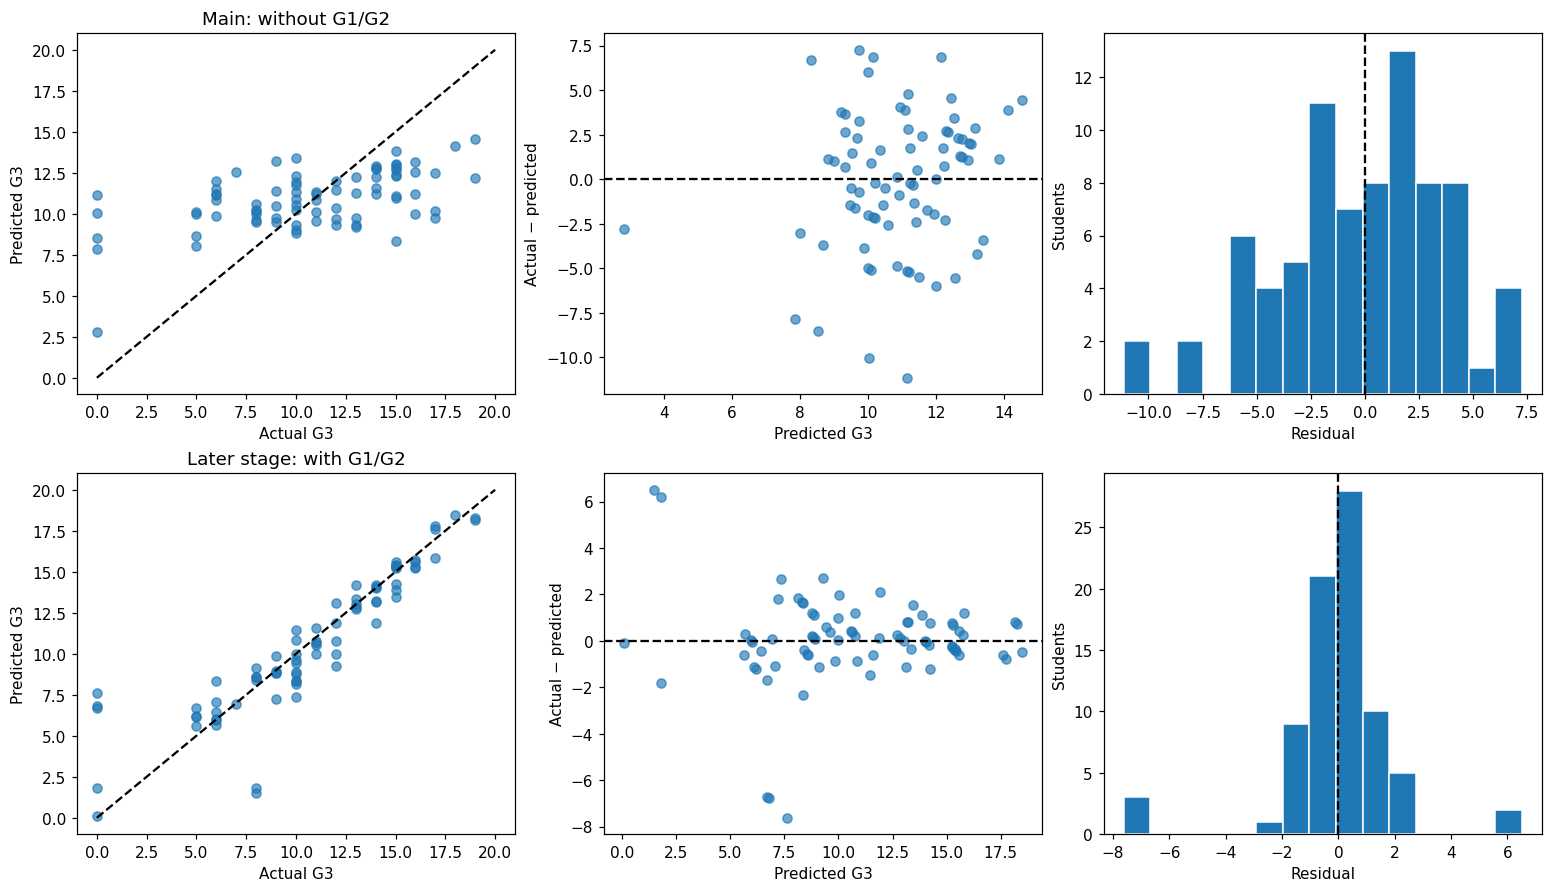

In [5]:
results = {}
for scenario, predicted in predictions.items():
    table = pd.DataFrame({"Actual G3": y_test, "Predicted G3": predicted})
    table.index.name = "Dataset row ID"
    table["Residual"] = table["Actual G3"] - table["Predicted G3"]
    table["Absolute error"] = table["Residual"].abs()
    table["Actual at risk"] = table["Actual G3"] < 10
    table["Flagged"] = table["Predicted G3"] < 10
    results[scenario] = table

fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
for row, (scenario, table) in enumerate(results.items()):
    axes[row, 0].scatter(table["Actual G3"], table["Predicted G3"], alpha=.65)
    axes[row, 0].plot([0, 20], [0, 20], "k--")
    axes[row, 0].set(title=labels[scenario], xlabel="Actual G3", ylabel="Predicted G3")
    axes[row, 1].scatter(table["Predicted G3"], table["Residual"], alpha=.65)
    axes[row, 1].axhline(0, color="black", linestyle="--")
    axes[row, 1].set(xlabel="Predicted G3", ylabel="Actual − predicted")
    axes[row, 2].hist(table["Residual"], bins=15, edgecolor="white")
    axes[row, 2].axvline(0, color="black", linestyle="--")
    axes[row, 2].set(xlabel="Residual", ylabel="Students")
plt.show()

### Check low grades and large errors

Observed grade groups diagnose mistakes retrospectively; G3 is never an input. Keep zero grades in the overall evaluation, with a separate group because their causes are unknown. A small average residual can conceal large errors in both directions.

In [6]:
error_rows = []
grade_rows = []
for scenario, table in results.items():
    error_rows.append({"Scenario": labels[scenario],
        "Mean residual": table["Residual"].mean(),
        "Median error": table["Absolute error"].median(),
        "90th percentile error": table["Absolute error"].quantile(.9),
        "Largest error": table["Absolute error"].max(),
        "Within 2 points (%)": table["Absolute error"].le(2).mean() * 100,
        "Outside 0–20": int((~table["Predicted G3"].between(0, 20)).sum())})
    groups = pd.cut(table["Actual G3"], [-1, 0, 9, 14, 20],
                    labels=["G3 = 0", "G3 = 1–9", "G3 = 10–14", "G3 = 15–20"])
    grouped = table.groupby(groups, observed=True).agg(
        Students=("Actual G3", "size"), MAE=("Absolute error", "mean"),
        Mean_residual=("Residual", "mean"))
    grouped.insert(0, "Scenario", labels[scenario])
    grade_rows.append(grouped)
display(pd.DataFrame(error_rows).round(3))
display(pd.concat(grade_rows).round(3))

,Scenario,Mean residual,Median error,90th percentile error,Largest error,Within 2 points (%),Outside 0–20
0,Main: without G1/G2,-0.133,2.414,6.136,11.148,37.975,0
1,Later stage: with G1/G2,0.022,0.693,2.144,7.621,88.608,0


,Scenario,Students,MAE,Mean_residual
Actual G3,,,,
G3 = 0,Main: without G1/G2,5,8.071,-8.071
G3 = 1–9,Main: without G1/G2,22,3.376,-3.376
G3 = 10–14,Main: without G1/G2,32,1.538,0.732
G3 = 15–20,Main: without G1/G2,20,4.034,4.034
G3 = 0,Later stage: with G1/G2,5,4.606,-4.606
G3 = 1–9,Later stage: with G1/G2,22,1.245,0.152
G3 = 10–14,Later stage: with G1/G2,32,0.912,0.548
G3 = 15–20,Later stage: with G1/G2,20,0.641,0.194


## 5 Evaluate the grade 10 risk rule

The positive class is **actual G3 < 10**. Flag a student when **predicted G3 < 10**; predicted 10 is not flagged.

Accuracy measures all correct decisions; precision measures how many flagged students really scored below 10; recall measures how many at-risk students were found. F1 combines precision and recall. Specificity measures correctly unflagged students scoring at least 10.

TP = correctly flagged; FP = unnecessary flag; FN = missed at-risk student; TN = correctly unflagged. Missing precision means no students were flagged. Compare flag-all and flag-none references, and keep the threshold fixed rather than optimize it using these test outcomes.

In [7]:
risk_columns = ["Accuracy", "Precision", "Recall", "F1", "Specificity", "TP", "FP", "FN", "TN"]
risk_predictions = {**all_predictions,
    "Flag every student": np.zeros(len(y_test)),
    "Flag no students": np.full(len(y_test), 20)}
risk_results = pd.DataFrame({name: {
    metric: flag_metric(y_test, predicted, metric) for metric in risk_columns
} for name, predicted in risk_predictions.items()}).T
risk_results["Flagged"] = risk_results["TP"] + risk_results["FP"]
display(risk_results.round(3))

,Accuracy,Precision,Recall,F1,Specificity,TP,FP,FN,TN,Flagged
Training mean baseline,0.658,NaN,0.000,0.000,1.000,0.0,0.0,27.0,52.0,0.0
Training median baseline,0.658,NaN,0.000,0.000,1.000,0.0,0.0,27.0,52.0,0.0
G2 unchanged (later stage only),0.911,0.812,0.963,0.881,0.885,26.0,6.0,1.0,46.0,32.0
Main: without G1/G2,0.646,0.476,0.370,0.417,0.788,10.0,11.0,17.0,41.0,21.0
Later stage: with G1/G2,0.873,0.730,1.000,0.844,0.808,27.0,10.0,0.0,42.0,37.0
Flag every student,0.342,0.342,1.000,0.509,0.000,27.0,52.0,0.0,0.0,79.0
Flag no students,0.658,NaN,0.000,0.000,1.000,0.0,0.0,27.0,52.0,0.0


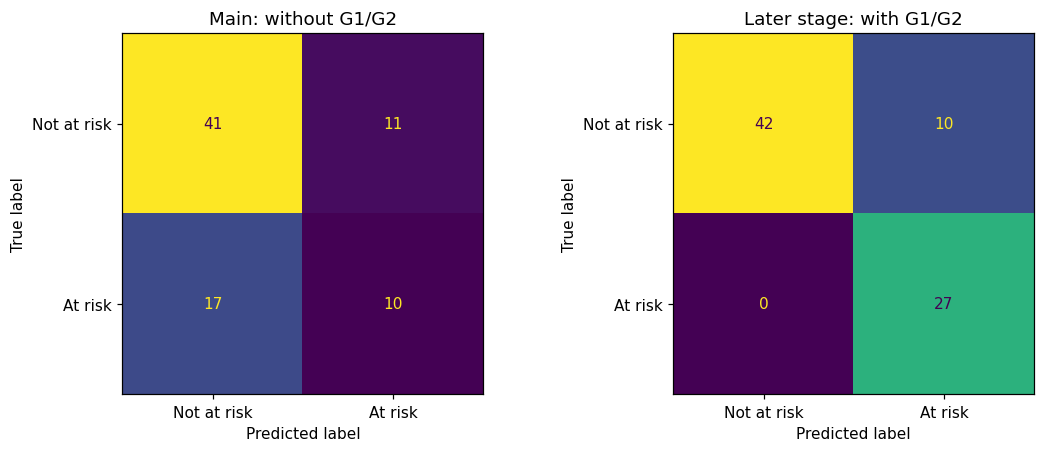

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for ax, (scenario, predicted) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test < 10, predicted < 10, labels=[False, True])
    ConfusionMatrixDisplay(cm, display_labels=["Not at risk", "At risk"]).plot(
        ax=ax, colorbar=False, values_format="d")
    ax.set_title(labels[scenario])
plt.show()

### Inspect individual cases

Review flagged students alongside missed at-risk students and the largest grade errors. Show up to ten rows per view to keep the notebook readable; complete test results remain in `results[scenario]`. Dataset row IDs are anonymous CSV positions, not a live student roster.

In [9]:
for scenario, table in results.items():
    print(labels[scenario], "— flagged students (up to 10)")
    display(table.loc[table["Flagged"]].sort_values("Predicted G3").head(10).round(3))
    print("Missed at-risk students (up to 10)")
    display(table.loc[table["Actual at risk"] & ~table["Flagged"]].head(10).round(3))
    print("Ten largest grade errors")
    display(table.nlargest(10, "Absolute error").round(3))

,Actual G3,Predicted G3,Residual,Absolute error,Actual at risk,Flagged
Dataset row ID,,,,,,
137,0,2.815,-2.815,2.815,True,True
334,0,7.841,-7.841,7.841,True,True
72,5,8.007,-3.007,3.007,True,True
324,15,8.323,6.677,6.677,False,True
168,0,8.530,-8.530,8.530,True,True
18,5,8.668,-3.668,3.668,True,True
157,10,8.838,1.162,1.162,False,True
78,10,9.003,0.997,0.997,False,True
223,13,9.211,3.789,3.789,False,True


,Actual G3,Predicted G3,Residual,Absolute error,Actual at risk,Flagged
Dataset row ID,,,,,,
248,5,10.087,-5.087,5.087,True,False
234,6,11.216,-5.216,5.216,True,False
316,0,10.021,-10.021,10.021,True,False
209,7,12.559,-5.559,5.559,True,False
155,8,10.592,-2.592,2.592,True,False
140,0,11.148,-11.148,11.148,True,False
307,8,10.141,-2.141,2.141,True,False
384,5,10.003,-5.003,5.003,True,False
25,8,10.000,-2.000,2.000,True,False


,Actual G3,Predicted G3,Residual,Absolute error,Actual at risk,Flagged
Dataset row ID,,,,,,
140,0,11.148,-11.148,11.148,True,False
316,0,10.021,-10.021,10.021,True,False
168,0,8.530,-8.530,8.530,True,True
334,0,7.841,-7.841,7.841,True,True
182,17,9.730,7.270,7.270,False,True
101,17,10.147,6.853,6.853,False,False
113,19,12.155,6.845,6.845,False,False
324,15,8.323,6.677,6.677,False,True
177,6,12.001,-6.001,6.001,True,False


,Actual G3,Predicted G3,Residual,Absolute error,Actual at risk,Flagged
Dataset row ID,,,,,,
137,0,0.093,-0.093,0.093,True,True
90,8,1.488,6.512,6.512,True,True
124,8,1.792,6.208,6.208,True,True
168,0,1.816,-1.816,1.816,True,True
18,5,5.618,-0.618,0.618,True,True
386,6,5.683,0.317,0.317,True,True
82,6,5.977,0.023,0.023,True,True
177,6,6.026,-0.026,0.026,True,True
384,5,6.123,-1.123,1.123,True,True


,Actual G3,Predicted G3,Residual,Absolute error,Actual at risk,Flagged
Dataset row ID,,,,,,


,Actual G3,Predicted G3,Residual,Absolute error,Actual at risk,Flagged
Dataset row ID,,,,,,
140,0,7.621,-7.621,7.621,True,True
334,0,6.787,-6.787,6.787,True,True
316,0,6.713,-6.713,6.713,True,True
90,8,1.488,6.512,6.512,True,True
124,8,1.792,6.208,6.208,True,True
33,12,9.275,2.725,2.725,False,True
93,10,7.355,2.645,2.645,False,True
45,6,8.342,-2.342,2.342,True,True
73,14,11.905,2.095,2.095,False,False


Main: without G1/G2 — flagged students (up to 10)
Missed at-risk students (up to 10)
Ten largest grade errors
Later stage: with G1/G2 — flagged students (up to 10)
Missed at-risk students (up to 10)
Ten largest grade errors


## 6 Descriptive group checks

Compare error and recall by recorded sex and school. The test groups are small; differences can suggest questions for a larger audit but cannot establish fairness or prove discrimination. No model or threshold is changed using these checks.

In [10]:
group_rows = []
for scenario, table in results.items():
    audit = table.join(df.loc[test_ids, ["sex", "school"]])
    for attribute in ["sex", "school"]:
        for group, subset in audit.groupby(attribute):
            group_rows.append({"Scenario": labels[scenario], "Attribute": attribute, "Group": group,
                "Students": len(subset), "Actual at risk": int(subset["Actual at risk"].sum()),
                "MAE": subset["Absolute error"].mean(),
                "Recall": flag_metric(subset["Actual G3"], subset["Predicted G3"], "Recall"),
                "Precision": flag_metric(subset["Actual G3"], subset["Predicted G3"], "Precision"),
                "Missed": flag_metric(subset["Actual G3"], subset["Predicted G3"], "FN")})
display(pd.DataFrame(group_rows).round(3))

,Scenario,Attribute,Group,Students,Actual at risk,MAE,Recall,Precision,Missed
0,Main: without G1/G2,sex,F,38,15,3.148,0.467,0.538,8
1,Main: without G1/G2,sex,M,41,12,3.046,0.250,0.375,9
2,Main: without G1/G2,school,GP,67,23,3.243,0.391,0.529,14
3,Main: without G1/G2,school,MS,12,4,2.271,0.250,0.250,3
4,Later stage: with G1/G2,sex,F,38,15,1.398,1.000,0.714,0
5,Later stage: with G1/G2,sex,M,41,12,0.959,1.000,0.750,0
6,Later stage: with G1/G2,school,GP,67,23,1.228,1.000,0.767,0
7,Later stage: with G1/G2,school,MS,12,4,0.844,1.000,0.571,0


## 7 Findings and recommendations

### Findings for the current frozen models

- The main model has test MAE **3.095**, RMSE **3.871** and R² **0.269**. It improves MAE by about **14.5%** over the training-median baseline, but misses **17 of 27** at-risk students and produces **11 false positives**.
- The G1/G2 model has MAE **1.170**, RMSE **1.975** and R² **0.810**. It finds all 27 at-risk students in this test sample with **10 false positives**. Perfect observed recall does not guarantee future recall.
- Using G2 unchanged has lower MAE (**1.000**) but higher RMSE (**2.072**) than the later-stage forest. G2 < 10 misses one student with six false positives. The forest catches one additional student at the cost of four additional unnecessary flags; it is not an unqualified improvement.
- The main model overpredicts low grades and underpredicts high grades. Errors remain large among the five zero-grade test students. Zero-grade causes remain unknown.

These interpretations describe the fixed evaluated models. If the models or data change, review the prose against the newly calculated tables; do not treat this used test set as unseen.

### Recommendations

1. Use predictions as one signal for supportive staff review. An unflagged student must still be able to receive assistance, especially given the main model's missed cases.
2. For flagged students, check data accuracy and current performance, speak with the student, and agree on suitable support such as tutoring, study planning or attendance assistance. Predictions do not diagnose a cause or establish lack of effort.
3. After G2 is available, compare a simple G2 review with the later-stage model, considering staff capacity and the cost of missed assistance versus unnecessary reviews.
4. Before a pilot, define a prediction date and confirm that every input is available then, particularly absences. Review whether personal and family attributes are necessary, restrict access, and allow correction of inaccurate data.
5. Validate on a new cohort, with larger subgroup samples and monitoring of missed support cases. If a different threshold is needed, develop it using training/validation data and evaluate it on new untouched data.

### Limitations and responsible use

The 395-student, two-school Mathematics sample and one 79-student random holdout limit generalization to other schools, subjects or years. Full-data EDA preceded the split, and selection reused training folds. The holdout was not fully blind to exploration.

Excluding G1/G2 does not establish early availability of the other inputs. The later-stage scenario requires both prior grades. Zero-grade causes and the source's failures-code meaning remain unresolved. Small subgroup checks do not establish fairness.

Predictions are point estimates, not probabilities or individual uncertainty intervals. MAE is an average, not a guarantee for one student. Associations do not show that changing a feature or offering an intervention causes a better grade.

Staff retain responsibility: do not use predictions automatically for discipline, grading, exclusion or denial of support. Further modelling requires new untouched evaluation data. No CSV, image or report files are exported by this notebook.